# 03. Phân tích thực nghiệm MCTS/UCT

Notebook khảo sát `MCTSAgent` trên bàn cờ Caro `11 × 11`, luật thắng **ít nhất 5 quân liên tiếp**. Thuật toán được import từ `src/`; notebook chỉ thiết lập thí nghiệm, thu thập số liệu và trực quan hóa.

## Nội dung

1. Kiểm tra môi trường và chạy smoke test MCTS.
2. Minh họa cây tìm kiếm và kiểm tra các tình huống chiến thuật.
3. Độ nhạy số lượt mô phỏng (`num_rollouts`) khi đấu với RuleBasedAgent (Cấp 2).
4. Độ nhạy hệ số khám phá (`exploration_c`) trên cùng tập thế cờ.
5. So sánh ngân sách fixed-rollouts, time-budget và combined.
6. Đối kháng 50 ván MCTS vs Minimax với ngân sách thời gian như nhau.
7. Phân tích Board Occupancy từ **một nhóm ván cụ thể**, không trộn nhiều cấu hình.
8. Explainability qua `get_root_stats()` và tổng kết kết quả.

**Quy tắc dữ liệu:** notebook không tạo Agent giả. Rollouts Sensitivity mặc định yêu cầu `RuleBasedAgent`; nếu chưa tích hợp, có thể chủ động chọn `MCTS N=30` làm baseline bổ sung trong Cell Setup. Khi đó kết quả phải được ghi rõ là MCTS-vs-MCTS N=30, không xem là kết quả đối kháng với RuleBasedAgent theo RQ2. Nếu `MinimaxAgent` chưa tích hợp, thí nghiệm MCTS vs Minimax sẽ hiện `PENDING INTEGRATION`. Mọi kết quả dùng trong báo cáo phải lấy từ CSV/JSONL sinh ra bởi lần chạy thực tế.

**Thực thi:** chạy notebook từ thư mục repository `caro_ai_11x11` (hoặc thư mục `notebooks/` bên trong repo). Nếu chạy Colab và notebook không tìm thấy `src/caro_env.py`, đặt `PROJECT_ROOT_OVERRIDE` trong Cell Setup trỏ đến thư mục repository đã clone hoặc mount.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')

    # Đường dẫn đến thư mục chứa notebook và các file trên Drive
    folder_path = '/content/drive/MyDrive/Advanced_AI/Final_PBL/caro_ai_11x11/notebooks'

    # Đổi thư mục làm việc hiện tại sang thư mục này
    os.chdir(folder_path)
    print("Your working directory is", os.getcwd())
except ImportError:
    pass

Mounted at /content/drive
Your working directory is /content/drive/MyDrive/Advanced_AI/Final_PBL/caro_ai_11x11/notebooks


In [2]:
# CELL 1 — SETUP VÀ CẤU HÌNH THÍ NGHIỆM
import csv
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Để None nếu notebook nằm trong repo và được mở từ thư mục repo/notebooks.
# Trên Colab có thể đặt, ví dụ: Path("/content/caro_ai_11x11")
PROJECT_ROOT_OVERRIDE = None


def find_project_root(start: Path | None = None, override: Path | None = None) -> Path:
    """Tìm thư mục chứa src/caro_env.py."""
    if override is not None:
        candidate = Path(override).expanduser().resolve()
        if (candidate / "src" / "caro_env.py").is_file():
            return candidate
        raise FileNotFoundError(
            f"PROJECT_ROOT_OVERRIDE không phải repository hợp lệ: {candidate}"
        )

    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "src" / "caro_env.py").is_file():
            return candidate

    # Trường hợp Colab mở notebook từ /content nhưng repo nằm ở /content/<repo>.
    common_candidates = [Path.cwd() / "caro_ai_11x11", Path("/content/caro_ai_11x11")]
    for candidate in common_candidates:
        candidate = candidate.resolve()
        if (candidate / "src" / "caro_env.py").is_file():
            return candidate

    raise FileNotFoundError(
        "Không tìm thấy src/caro_env.py. Hãy chạy notebook từ repository "
        "caro_ai_11x11 hoặc đặt PROJECT_ROOT_OVERRIDE đúng đường dẫn."
    )


PROJECT_ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SRC_DIR = PROJECT_ROOT / "src"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
TAB_DIR = RESULTS_DIR / "tables"
LOG_DIR = RESULTS_DIR / "logs"
for folder in (RESULTS_DIR, FIG_DIR, TAB_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from caro_env import CaroEnv
from heuristic import evaluate_cell_threat, get_candidate_actions
from agents.mcts_agent import MCTSAgent

# Các lớp này có thể chưa tồn tại trong nhánh hiện tại.
try:
    from agents.rule_based_agent import RuleBasedAgent
except (ImportError, AttributeError):
    RuleBasedAgent = None

try:
    from agents.minimax_agent import MinimaxAgent
except (ImportError, AttributeError):
    MinimaxAgent = None

# Chỉ khai báo factory sau khi đã tích hợp Agent và xác nhận constructor.
# Ví dụ nếu constructor khớp:
# RULE_BASED_AGENT_FACTORY = lambda seed: RuleBasedAgent(seed=seed)
# MINIMAX_AGENT_FACTORY = lambda time_limit_sec, seed: MinimaxAgent(
#     time_limit_sec=time_limit_sec, seed=seed
# )
RULE_BASED_AGENT_FACTORY = None
MINIMAX_AGENT_FACTORY = None

# ---------------- CẤU HÌNH CÓ THỂ ĐIỀU CHỈNH ----------------
BASE_SEED = 2026

# Rollouts Sensitivity: giữ C=1.414, tắt giới hạn thời gian.
ROLLOUT_BUDGETS = [50, 150, 300, 600]
ROLLOUT_SENSITIVITY_C = 1.414
ROLLOUT_GAMES_PER_SETTING = 20  # số chẵn: cân bằng X/O
# Chọn đối thủ cho Rollouts Sensitivity:
#   "rule_based" : thí nghiệm chính theo RQ2 (cần tích hợp RuleBasedAgent + factory).
#   "mcts_30"    : thí nghiệm bổ sung, so sánh MCTS N={50,150,300,600} với MCTS N=30.
# Không tự động fallback để tránh thay đổi ý nghĩa thí nghiệm mà không nhận ra.
ROLLOUT_BASELINE_MODE = "mcts_30"  # đổi thành "mcts_30" nếu chưa có RuleBasedAgent
MCTS_BASELINE_ROLLOUTS = 30

# Exploration Constant Sensitivity: cố định ngân sách rollout.
EXPLORATION_VALUES = [0.0, 0.5, 1.414, 3.0]
C_SENSITIVITY_ROLLOUTS = 200

# Budget Comparison: ba chế độ dùng cùng tập thế cờ.
BUDGET_FIXED_ROLLOUTS = 250
BUDGET_TIME_LIMIT_SEC = 0.15
BENCHMARK_POSITION_COUNT = 8

# MCTS vs Minimax: 50 ván, hai bên đi trước cân bằng.
MINIMAX_GAMES = 50
MINIMAX_TIME_BUDGET_SEC = 0.5

# Các thí nghiệm minh họa / kiểm tra.
TREE_WALKTHROUGH_BUDGETS = [1, 5, 15, 35, 100, 300]
TACTICAL_TEST_ROLLOUTS = 100
OPEN_THREE_TEST_ROLLOUTS = 300
EXPLAINABILITY_ROLLOUTS = 300
EXPLAINABILITY_C = 1.414
OCCUPANCY_FALLBACK_ROLLOUT_BUDGET = 600

print(f"Project root: {PROJECT_ROOT}")
print(f"MCTSAgent: {MCTSAgent.__module__}.{MCTSAgent.__name__}")
print(f"RuleBasedAgent: {'available' if RuleBasedAgent is not None else 'PENDING INTEGRATION'}")
print(f"Rollouts baseline mode: {ROLLOUT_BASELINE_MODE}")
print(f"MinimaxAgent: {'available' if MinimaxAgent is not None else 'PENDING INTEGRATION'}")
print("Kết quả sẽ được lưu trong:", RESULTS_DIR)


Project root: /content/drive/MyDrive/Advanced_AI/Final_PBL/caro_ai_11x11
MCTSAgent: agents.mcts_agent.MCTSAgent
RuleBasedAgent: PENDING INTEGRATION
Rollouts baseline mode: mcts_30
MinimaxAgent: PENDING INTEGRATION
Kết quả sẽ được lưu trong: /content/drive/MyDrive/Advanced_AI/Final_PBL/caro_ai_11x11/results


## 0. Smoke Test — kiểm tra nhanh môi trường và MCTS

Ô này chỉ xác nhận import thành công, `select_action()` trả về một nước hợp lệ và MCTS không làm thay đổi bàn cờ gốc. Đây **không phải** thí nghiệm đo hiệu năng hay dùng làm kết quả báo cáo.

In [3]:
# Smoke test độc lập — có thể chạy trước khi chạy toàn bộ notebook.
smoke_env = CaroEnv(board_size=11, win_length=5)
for action in [60, 61, 49, 38, 71, 72]:
    if smoke_env.is_terminal():
        raise RuntimeError("Thế cờ smoke test kết thúc ngoài dự kiến.")
    smoke_env.step(action)

smoke_board_before = smoke_env.board.copy()
smoke_player_before = smoke_env.current_player
smoke_agent = MCTSAgent(
    num_rollouts=25,
    exploration_c=ROLLOUT_SENSITIVITY_C,
    time_limit_sec=None,
    seed=BASE_SEED,
    name="MCTS_SmokeTest",
)
smoke_action = smoke_agent.select_action(smoke_env)

assert smoke_action in smoke_env.legal_actions(), "MCTS trả về nước không hợp lệ."
assert np.array_equal(smoke_env.board, smoke_board_before), "MCTS đã làm thay đổi board gốc."
assert smoke_env.current_player == smoke_player_before, "MCTS đã làm thay đổi lượt chơi gốc."
print({
    "status": "PASS",
    "selected_action": int(smoke_action),
    "row_col": divmod(int(smoke_action), 11),
    "actual_rollouts": smoke_agent.last_search_count,
    "move_time_ms": round(smoke_agent.last_move_time_ms, 3),
    "root_available": smoke_agent.last_root is not None,
})


{'status': 'PASS', 'selected_action': 58, 'row_col': (5, 3), 'actual_rollouts': 25, 'move_time_ms': 45.879, 'root_available': True}


In [4]:
# CELL 2 — HÀM HỖ TRỢ, GHI KẾT QUẢ VÀ TẠO TẬP THẾ CỜ

def save_csv(filepath: Path, rows: list[dict]) -> None:
    """Ghi danh sách bản ghi thành CSV; không tạo file rỗng."""
    if not rows:
        print(f"Không có dữ liệu để ghi: {filepath.name}")
        return
    fieldnames = list(dict.fromkeys(key for row in rows for key in row.keys()))
    with filepath.open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def save_jsonl(filepath: Path, records: list[dict]) -> None:
    """Ghi log từng ván theo định dạng JSON Lines."""
    if not records:
        print(f"Không có log để ghi: {filepath.name}")
        return
    with filepath.open("w", encoding="utf-8") as file:
        for record in records:
            file.write(json.dumps(record, ensure_ascii=False) + "\n")


def wilson_interval_95(wins: int, total: int) -> tuple[float, float]:
    """Khoảng Wilson 95% cho tỷ lệ thắng W/N, đơn vị phần trăm."""
    if total <= 0:
        return 0.0, 0.0
    z = 1.96
    p = wins / total
    denominator = 1.0 + z**2 / total
    center = (p + z**2 / (2.0 * total)) / denominator
    margin = z * math.sqrt(p * (1.0 - p) / total + z**2 / (4.0 * total**2)) / denominator
    return max(0.0, center - margin) * 100.0, min(1.0, center + margin) * 100.0


def bootstrap_interval_95(
    game_scores: list[float], n_boot: int = 4000, seed: int = BASE_SEED
) -> tuple[float, float]:
    """Khoảng bootstrap 95% cho score rate; mỗi ván có điểm 0, 0.5 hoặc 1."""
    if not game_scores:
        return 0.0, 0.0
    values = np.asarray(game_scores, dtype=np.float64)
    if np.all(values == values[0]):
        value = float(values[0] * 100.0)
        return value, value
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
    low, high = np.percentile(samples.mean(axis=1) * 100.0, [2.5, 97.5])
    return float(low), float(high)


def run_match_series(
    agent_a,
    agent_b,
    num_games: int,
    series_name: str,
    base_seed: int = BASE_SEED,
) -> tuple[dict, list[dict]]:
    """Chạy đối kháng cân bằng X/O; ghi từng nước, thời gian và số rollout."""
    if not isinstance(num_games, int) or num_games <= 0 or num_games % 2 != 0:
        raise ValueError("num_games phải là số nguyên dương chẵn để cân bằng X/O.")

    env = CaroEnv(board_size=11, win_length=5)
    wins = draws = losses = 0
    wins_as_x = wins_as_o = 0
    score_list: list[float] = []
    game_lengths: list[int] = []
    a_times_ms: list[float] = []
    a_rollouts: list[int] = []
    a_shortcuts = 0
    records: list[dict] = []

    name_a = getattr(agent_a, "name", type(agent_a).__name__)
    name_b = getattr(agent_b, "name", type(agent_b).__name__)

    for game_index in range(num_games):
        game_seed = base_seed + game_index * 101
        # Làm mới RNG của Agent nếu lớp đó có thuộc tính rng.
        for agent, offset in ((agent_a, 1), (agent_b, 2)):
            if hasattr(agent, "rng"):
                agent.rng = np.random.default_rng(game_seed + offset)

        env.reset()
        a_player = 1 if game_index % 2 == 0 else -1
        moves = []
        ply = 1

        while not env.is_terminal():
            player = env.current_player
            current_agent = agent_a if player == a_player else agent_b
            agent_name = getattr(current_agent, "name", type(current_agent).__name__)

            start_time = time.perf_counter()
            action = int(current_agent.select_action(env))
            measured_ms = (time.perf_counter() - start_time) * 1000.0
            legal_actions = env.legal_actions()
            if action not in legal_actions:
                raise ValueError(
                    f"{agent_name} trả về action={action} không hợp lệ ở ván {game_index + 1}, ply={ply}."
                )

            raw_search_count = getattr(current_agent, "last_search_count", None)
            search_count = int(raw_search_count) if raw_search_count is not None else None
            reported_ms = getattr(current_agent, "last_move_time_ms", None)
            reported_ms = float(reported_ms) if reported_ms is not None else None

            if current_agent is agent_a:
                a_times_ms.append(measured_ms)
                if search_count is not None:
                    a_rollouts.append(search_count)
                    if search_count == 0:
                        a_shortcuts += 1

            env.step(action)
            moves.append({
                "ply": ply,
                "player": int(player),
                "agent": agent_name,
                "action": action,
                "row": action // 11,
                "col": action % 11,
                "move_time_ms": round(measured_ms, 3),
                "agent_reported_move_time_ms": round(reported_ms, 3) if reported_ms is not None else None,
                "search_count": search_count,
            })
            ply += 1

        result_a = env.result(perspective=a_player)
        if result_a > 0:
            wins += 1
            score_list.append(1.0)
            wins_as_x += int(a_player == 1)
            wins_as_o += int(a_player == -1)
        elif result_a < 0:
            losses += 1
            score_list.append(0.0)
        else:
            draws += 1
            score_list.append(0.5)

        game_lengths.append(len(env.history))
        records.append({
            "series": series_name,
            "game_id": game_index + 1,
            "seed": game_seed,
            "agent_a": name_a,
            "agent_b": name_b,
            "agent_x": name_a if a_player == 1 else name_b,
            "agent_o": name_b if a_player == 1 else name_a,
            "a_player": a_player,
            "winner": int(env.winner),
            "result_for_a": float(result_a),
            "total_plies": len(env.history),
            "moves": moves,
        })

    win_low, win_high = wilson_interval_95(wins, num_games)
    score_rate = float(np.mean(score_list) * 100.0)
    score_low, score_high = bootstrap_interval_95(score_list, seed=base_seed)
    active_rollouts = [value for value in a_rollouts if value > 0]

    summary = {
        "series": series_name,
        "agent_a": name_a,
        "agent_b": name_b,
        "games": num_games,
        "wins": wins,
        "draws": draws,
        "losses": losses,
        "wins_as_x": wins_as_x,
        "wins_as_o": wins_as_o,
        "win_rate_pct": round(wins / num_games * 100.0, 2),
        "win_ci_low_pct": round(win_low, 2),
        "win_ci_high_pct": round(win_high, 2),
        "score_rate_pct": round(score_rate, 2),
        "score_ci_low_pct": round(score_low, 2),
        "score_ci_high_pct": round(score_high, 2),
        "mean_plies": round(float(np.mean(game_lengths)), 2),
        # Dùng wall-clock đo bên ngoài select_action để thống nhất giữa các Agent.
        "mean_move_time_ms": round(float(np.mean(a_times_ms)), 3) if a_times_ms else None,
        "p95_move_time_ms": round(float(np.percentile(a_times_ms, 95)), 3) if a_times_ms else None,
        "mean_rollouts_active": round(float(np.mean(active_rollouts)), 2) if active_rollouts else None,
        "shortcut_or_forced_moves": a_shortcuts,
    }
    return summary, records


def build_position(actions: list[int]) -> CaroEnv:
    """Dựng một thế cờ từ danh sách action theo thứ tự X/O luân phiên."""
    env = CaroEnv(board_size=11, win_length=5)
    for action in actions:
        if env.is_terminal():
            raise ValueError("Chuỗi action tạo ván kết thúc trước khi hoàn tất thế cờ.")
        env.step(int(action))
    return env


def make_benchmark_positions(count: int = BENCHMARK_POSITION_COUNT) -> list[CaroEnv]:
    """Tạo các thế cờ không kết thúc bằng seed cố định; mọi cấu hình dùng chung tập này."""
    if count <= 0:
        raise ValueError("BENCHMARK_POSITION_COUNT phải lớn hơn 0.")
    positions = []
    move_counts = np.linspace(8, 28, count, dtype=int)
    for index, target_moves in enumerate(move_counts):
        rng = np.random.default_rng(BASE_SEED + index)
        env = CaroEnv(board_size=11, win_length=5)
        for _ in range(int(target_moves)):
            if env.is_terminal():
                break
            legal = env.legal_actions()
            if not legal:
                break
            env.step(int(rng.choice(legal)))
        if not env.is_terminal() and env.history:
            positions.append(env)
    return positions


benchmark_positions = make_benchmark_positions()
print(f"Đã tạo {len(benchmark_positions)} thế cờ kiểm tra cố định.")
if not benchmark_positions:
    raise RuntimeError("Không tạo được benchmark position nào.")


Đã tạo 8 thế cờ kiểm tra cố định.


## 1. Cơ sở thuật toán và minh họa cây tìm kiếm

MCTS/UCT thực hiện bốn giai đoạn:

1. **Selection:** đi từ nút gốc xuống nút con theo điểm UCT.
2. **Expansion:** mở rộng một hành động chưa thử. Tập hành động được lọc bởi `candidate_radius`.
3. **Simulation (Rollout):** mô phỏng tiếp bằng `_rollout_policy`, dùng `rollout_radius` và giới hạn `max_rollout_steps`.
4. **Backpropagation:** cập nhật `visits` và `wins` dọc đường từ nút vừa mở rộng về nút gốc.

Trong implementation hiện tại, `wins` được cộng `+1` nếu người vừa đi thắng rollout và `-1` nếu người vừa đi thua; rollout chưa phân định kết quả trả về `0`. Vì vậy `W_i / n_i` là giá trị tích lũy có thể nằm trong `[-1, 1]`, không nhất thiết là xác suất thắng `[0, 1]`.

Công thức UCT được dùng có dạng:

\[
UCT_i = \frac{W_i}{n_i} + C\sqrt{\frac{\ln N}{n_i}}
\]

Với cấu hình hiện tại của `MCTSAgent`: `candidate_radius=2`, `rollout_radius=1`, `max_rollout_steps=30`. Khi rollout dừng mà ván chưa kết thúc, kết quả mô phỏng là `0.0`; đây là kết quả chưa phân định trong rollout, không phải một chiến thắng.

Thí nghiệm dưới đây dùng một thế cờ cố định, thay đổi số rollout và quan sát số nhánh mở rộng, số lượt thăm tại nút gốc và thời gian.

{'num_rollouts_limit': 1, 'actual_rollouts': 1, 'root_visits': 1, 'expanded_children': 1, 'untried_actions_left': 47, 'selected_action': 91, 'selected_row': 8, 'selected_col': 3, 'top_branch_visits': 1, 'top_branch_value': 1.0, 'move_time_ms': 5.755}
{'num_rollouts_limit': 5, 'actual_rollouts': 5, 'root_visits': 5, 'expanded_children': 5, 'untried_actions_left': 43, 'selected_action': 91, 'selected_row': 8, 'selected_col': 3, 'top_branch_visits': 1, 'top_branch_value': 1.0, 'move_time_ms': 17.159}
{'num_rollouts_limit': 15, 'actual_rollouts': 15, 'root_visits': 15, 'expanded_children': 15, 'untried_actions_left': 33, 'selected_action': 91, 'selected_row': 8, 'selected_col': 3, 'top_branch_visits': 1, 'top_branch_value': 1.0, 'move_time_ms': 27.227}
{'num_rollouts_limit': 35, 'actual_rollouts': 35, 'root_visits': 35, 'expanded_children': 35, 'untried_actions_left': 13, 'selected_action': 91, 'selected_row': 8, 'selected_col': 3, 'top_branch_visits': 1, 'top_branch_value': 1.0, 'move_tim

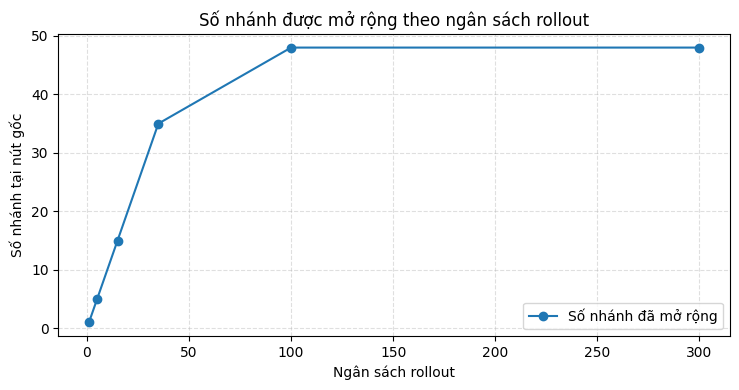

In [5]:
# Thế cờ trung cuộc dùng cho phần minh họa cây.
walkthrough_env = build_position([60, 49, 59, 48, 72, 71, 47, 38])
walkthrough_rows = []

for rollout_count in TREE_WALKTHROUGH_BUDGETS:
    demo_agent = MCTSAgent(
        num_rollouts=rollout_count,
        exploration_c=ROLLOUT_SENSITIVITY_C,
        time_limit_sec=None,
        seed=BASE_SEED,
        name=f"MCTS_Tree_N{rollout_count}",
    )
    selected_action = demo_agent.select_action(walkthrough_env.clone())
    root = demo_agent.last_root
    root_stats = demo_agent.get_root_stats()
    top_branch = root_stats[0] if root_stats else None

    walkthrough_rows.append({
        "num_rollouts_limit": rollout_count,
        "actual_rollouts": demo_agent.last_search_count,
        "root_visits": root.visits if root is not None else 0,
        "expanded_children": len(root.children) if root is not None else 0,
        "untried_actions_left": len(root.untried_actions) if root is not None else None,
        "selected_action": int(selected_action),
        "selected_row": int(selected_action) // 11,
        "selected_col": int(selected_action) % 11,
        "top_branch_visits": top_branch["visits"] if top_branch else None,
        "top_branch_value": round(top_branch["value"], 4) if top_branch else None,
        "move_time_ms": round(demo_agent.last_move_time_ms, 3),
    })

save_csv(TAB_DIR / "03_table_mcts_tree_walkthrough.csv", walkthrough_rows)
for row in walkthrough_rows:
    print(row)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(
    [row["num_rollouts_limit"] for row in walkthrough_rows],
    [row["expanded_children"] for row in walkthrough_rows],
    marker="o",
    label="Số nhánh đã mở rộng",
)
ax.set_xlabel("Ngân sách rollout")
ax.set_ylabel("Số nhánh tại nút gốc")
ax.set_title("Số nhánh được mở rộng theo ngân sách rollout")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_fig_mcts_tree_walkthrough.png", dpi=150)
plt.show()


## 2. Kiểm tra một số tình huống chiến thuật

Bốn tình huống được kiểm tra:

- **Empty board:** chỉ có một nước ứng viên ở tâm bàn cờ.
- **Win-in-1:** X có thể tạo đủ 5 quân trong nước kế tiếp.
- **Block-in-1:** X phải chặn nước thắng ngay của O.
- **Open-3:** kiểm tra `evaluate_cell_threat` có nhận diện việc nối chuỗi 3 mở thành chuỗi 4 mở hai đầu hay không.

Với ba trường hợp đầu, notebook kiểm tra action được chọn và trạng thái shortcut. Với `Open-3`, notebook xác nhận điểm mẫu hình bằng hàm đánh giá; không coi đó là một nước bắt buộc của MCTS.

In [6]:
# 1. Bàn cờ trống.
empty_env = CaroEnv(board_size=11, win_length=5)
empty_agent = MCTSAgent(num_rollouts=TACTICAL_TEST_ROLLOUTS, seed=BASE_SEED)
empty_action = empty_agent.select_action(empty_env)

# 2. X có bốn quân liên tiếp ở hàng 5; tới lượt X.
win_env = build_position([55, 0, 56, 2, 57, 22, 58, 24])
win_agent = MCTSAgent(num_rollouts=TACTICAL_TEST_ROLLOUTS, seed=BASE_SEED)
win_action = win_agent.select_action(win_env)

# 3. O có bốn quân liên tiếp ở hàng 6; tới lượt X.
block_env = build_position([0, 66, 2, 67, 22, 68, 24, 69])
block_agent = MCTSAgent(num_rollouts=TACTICAL_TEST_ROLLOUTS, seed=BASE_SEED)
block_action = block_agent.select_action(block_env)

# 4. X có chuỗi 3 mở hai đầu; tới lượt X.
open_three_env = build_position([60, 37, 59, 38, 61, 82, 10, 20])
open_three_candidates = [58, 62]
open_three_checks = {
    action: evaluate_cell_threat(open_three_env, action, player=1)
    for action in open_three_candidates
}
open_three_agent = MCTSAgent(num_rollouts=OPEN_THREE_TEST_ROLLOUTS, seed=BASE_SEED)
open_three_selected = open_three_agent.select_action(open_three_env)

tactical_rows = [
    {
        "scenario": "Empty board",
        "expected_action": 60,
        "selected_action": int(empty_action),
        "condition_met": int(empty_action) == 60,
        "search_count": empty_agent.last_search_count,
        "last_root_is_none": empty_agent.last_root is None,
    },
    {
        "scenario": "Win-in-1",
        "expected_action": 59,
        "selected_action": int(win_action),
        "condition_met": int(win_action) == 59,
        "search_count": win_agent.last_search_count,
        "last_root_is_none": win_agent.last_root is None,
    },
    {
        "scenario": "Block-in-1",
        "expected_action": 70,
        "selected_action": int(block_action),
        "condition_met": int(block_action) == 70,
        "search_count": block_agent.last_search_count,
        "last_root_is_none": block_agent.last_root is None,
    },
    {
        "scenario": "Open-3 pattern evaluation",
        "expected_action": "58 or 62 has open_4 >= 1",
        "selected_action": int(open_three_selected),
        "condition_met": all(
            open_three_checks[action]["open_4"] >= 1
            for action in open_three_candidates
        ),
        "search_count": open_three_agent.last_search_count,
        "last_root_is_none": open_three_agent.last_root is None,
    },
]

save_csv(TAB_DIR / "03_table_tactical_checks.csv", tactical_rows)
for row in tactical_rows:
    print(row)

print("\nOpen-3 pattern details:")
for action, details in open_three_checks.items():
    print(
        f"action={action} -> open_4={details['open_4']}, "
        f"half_open_4={details['half_open_4']}, score={details['score']}"
    )


{'scenario': 'Empty board', 'expected_action': 60, 'selected_action': 60, 'condition_met': True, 'search_count': 0, 'last_root_is_none': True}
{'scenario': 'Win-in-1', 'expected_action': 59, 'selected_action': 59, 'condition_met': True, 'search_count': 0, 'last_root_is_none': True}
{'scenario': 'Block-in-1', 'expected_action': 70, 'selected_action': 70, 'condition_met': True, 'search_count': 0, 'last_root_is_none': True}
{'scenario': 'Open-3 pattern evaluation', 'expected_action': '58 or 62 has open_4 >= 1', 'selected_action': 58, 'condition_met': True, 'search_count': 300, 'last_root_is_none': False}

Open-3 pattern details:
action=58 -> open_4=1, half_open_4=0, score=15000.0
action=62 -> open_4=1, half_open_4=0, score=15000.0


## 3. Độ nhạy theo số lượt mô phỏng (`num_rollouts`)

Mục tiêu là quan sát sự thay đổi về **Win Rate** và **thời gian suy nghĩ** khi tăng ngân sách rollout. Đối thủ chính theo RQ2 là `RuleBasedAgent` (Cấp 2). Trong Cell Setup có thể chọn `ROLLOUT_BASELINE_MODE = "mcts_30"` để chạy thêm phép so sánh với MCTS N=30 khi RuleBasedAgent chưa sẵn sàng.

Mỗi cấu hình dùng số ván chẵn và đổi bên sau mỗi ván. `exploration_c` được cố định tại `ROLLOUT_SENSITIVITY_C`; `time_limit_sec=None` để cô lập ảnh hưởng của số rollout. Bảng kết quả có cả:

- **Win Rate:** số ván thắng / tổng số ván; hòa không tính là thắng.
- **Score Rate:** thắng = 1, hòa = 0.5, thua = 0.
- **Mean Move Time:** thời gian wall-clock trung bình của mỗi lần gọi `select_action`.

Trong mã nguồn ZIP đang dùng, `src/agents/rule_based_agent.py` chưa có lớp `RuleBasedAgent`. Vì vậy phần dưới sẽ dừng ở `PENDING INTEGRATION` cho đến khi nhóm tích hợp lớp này và khai báo `RULE_BASED_AGENT_FACTORY`. Không tự động thay đối thủ bằng MCTS N=30.

N=50 vs MCTS_N30: W/D/L=10/0/10, Win Rate=50.0%, Score Rate=50.0%, Mean Time=119.38 ms
N=150 vs MCTS_N30: W/D/L=15/0/5, Win Rate=75.0%, Score Rate=75.0%, Mean Time=318.305 ms
N=300 vs MCTS_N30: W/D/L=18/0/2, Win Rate=90.0%, Score Rate=90.0%, Mean Time=634.144 ms
N=600 vs MCTS_N30: W/D/L=18/0/2, Win Rate=90.0%, Score Rate=90.0%, Mean Time=1142.8 ms


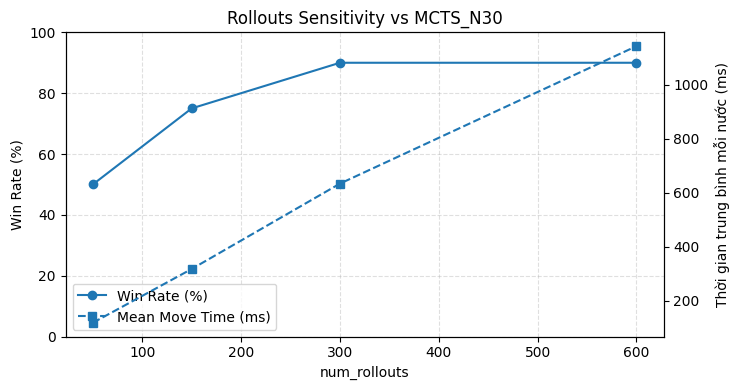

In [7]:
rollout_sensitivity_rows = []
rollout_match_records = []

if ROLLOUT_BASELINE_MODE not in {"rule_based", "mcts_30"}:
    raise ValueError("ROLLOUT_BASELINE_MODE phải là 'rule_based' hoặc 'mcts_30'.")

if ROLLOUT_BASELINE_MODE == "rule_based":
    rollout_opponent_tag = "RuleBased"
    if RuleBasedAgent is None or RULE_BASED_AGENT_FACTORY is None:
        print(
            "PENDING INTEGRATION: chưa có RuleBasedAgent/factory. "
            "Đổi ROLLOUT_BASELINE_MODE = 'mcts_30' để chạy thí nghiệm bổ sung."
        )
    else:
        rollout_baseline_ready = True
else:
    if not isinstance(MCTS_BASELINE_ROLLOUTS, int) or MCTS_BASELINE_ROLLOUTS <= 0:
        raise ValueError("MCTS_BASELINE_ROLLOUTS phải là số nguyên dương.")
    rollout_opponent_tag = f"MCTS_N{MCTS_BASELINE_ROLLOUTS}"
    rollout_baseline_ready = True

if ROLLOUT_BASELINE_MODE == "rule_based" and RuleBasedAgent is not None and RULE_BASED_AGENT_FACTORY is not None:
    rollout_baseline_ready = True
elif ROLLOUT_BASELINE_MODE == "rule_based":
    rollout_baseline_ready = False

if rollout_baseline_ready:
    for index, rollout_count in enumerate(ROLLOUT_BUDGETS):
        mcts_agent = MCTSAgent(
            num_rollouts=rollout_count,
            exploration_c=ROLLOUT_SENSITIVITY_C,
            time_limit_sec=None,
            seed=BASE_SEED,
            name=f"MCTS_N{rollout_count}",
        )

        if ROLLOUT_BASELINE_MODE == "rule_based":
            opponent_agent = RULE_BASED_AGENT_FACTORY(BASE_SEED + index + 1)
            if not callable(getattr(opponent_agent, "select_action", None)):
                raise TypeError("RULE_BASED_AGENT_FACTORY phải trả về Agent có select_action(env).")
        else:
            opponent_agent = MCTSAgent(
                num_rollouts=MCTS_BASELINE_ROLLOUTS,
                exploration_c=ROLLOUT_SENSITIVITY_C,
                time_limit_sec=None,
                seed=BASE_SEED + index + 1,
                name=f"MCTS_Baseline_N{MCTS_BASELINE_ROLLOUTS}",
            )

        series_name = f"MCTS_N{rollout_count}_vs_{rollout_opponent_tag}"
        summary, records = run_match_series(
            agent_a=mcts_agent,
            agent_b=opponent_agent,
            num_games=ROLLOUT_GAMES_PER_SETTING,
            series_name=series_name,
            base_seed=BASE_SEED + 1000 + index * 100,
        )
        summary["num_rollouts"] = rollout_count
        summary["exploration_c"] = ROLLOUT_SENSITIVITY_C
        summary["time_limit_sec"] = None
        summary["baseline_mode"] = ROLLOUT_BASELINE_MODE
        summary["baseline_name"] = rollout_opponent_tag
        rollout_sensitivity_rows.append(summary)
        rollout_match_records.extend(records)

        print(
            f"N={rollout_count} vs {rollout_opponent_tag}: "
            f"W/D/L={summary['wins']}/{summary['draws']}/{summary['losses']}, "
            f"Win Rate={summary['win_rate_pct']:.1f}%, "
            f"Score Rate={summary['score_rate_pct']:.1f}%, "
            f"Mean Time={summary['mean_move_time_ms']} ms"
        )

if rollout_sensitivity_rows:
    save_csv(TAB_DIR / "03_table_rollouts_sensitivity.csv", rollout_sensitivity_rows)
    save_jsonl(LOG_DIR / "03_logs_rollouts_sensitivity.jsonl", rollout_match_records)

    x_values = [row["num_rollouts"] for row in rollout_sensitivity_rows]
    win_values = [row["win_rate_pct"] for row in rollout_sensitivity_rows]
    time_values = [row["mean_move_time_ms"] for row in rollout_sensitivity_rows]
    fig, ax1 = plt.subplots(figsize=(7.5, 4))
    ax1.plot(x_values, win_values, "o-", label="Win Rate (%)")
    ax1.set_xlabel("num_rollouts")
    ax1.set_ylabel("Win Rate (%)")
    ax1.set_ylim(0, 100)
    ax1.grid(True, linestyle="--", alpha=0.4)
    ax2 = ax1.twinx()
    ax2.plot(x_values, time_values, "s--", label="Mean Move Time (ms)")
    ax2.set_ylabel("Thời gian trung bình mỗi nước (ms)")
    ax1.set_title(f"Rollouts Sensitivity vs {rollout_opponent_tag}")
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines], loc="best")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_fig_rollouts_sensitivity.png", dpi=150)
    plt.show()
else:
    print("Chưa có bảng/biểu đồ Rollouts Sensitivity vì baseline đang PENDING.")


## 4. Độ nhạy theo hệ số khám phá (`exploration_c`)

`exploration_c` điều chỉnh trọng số của thành phần khám phá trong UCT. Giá trị nhỏ thiên về khai thác các nhánh đã có giá trị; giá trị lớn tăng mức ưu tiên thử các nhánh ít được thăm.

Phần này cố định `num_rollouts = C_SENSITIVITY_ROLLOUTS` và chạy từng cấu hình trên **cùng tập thế cờ** (`benchmark_positions`). Không có đối thủ trong thí nghiệm này; đây là phân tích hành vi tìm kiếm, không phải phép đo Win Rate hay sức mạnh thi đấu.

Các chỉ số: action được chọn, thời gian, rollout thực tế, số nhánh tại root, tỷ trọng lượt thăm của nhánh đứng đầu và entropy phân bố lượt thăm.

{'exploration_c': 0.0, 'positions': 8, 'mean_move_time_ms': 589.914, 'mean_actual_rollouts_active': 200.0, 'mean_top_visit_share_pct': 32.43, 'mean_visit_entropy': 3.3578}
{'exploration_c': 0.5, 'positions': 8, 'mean_move_time_ms': 407.153, 'mean_actual_rollouts_active': 200.0, 'mean_top_visit_share_pct': 3.14, 'mean_visit_entropy': 4.4206}
{'exploration_c': 1.414, 'positions': 8, 'mean_move_time_ms': 405.815, 'mean_actual_rollouts_active': 200.0, 'mean_top_visit_share_pct': 1.71, 'mean_visit_entropy': 4.4707}
{'exploration_c': 3.0, 'positions': 8, 'mean_move_time_ms': 485.039, 'mean_actual_rollouts_active': 200.0, 'mean_top_visit_share_pct': 1.57, 'mean_visit_entropy': 4.4935}


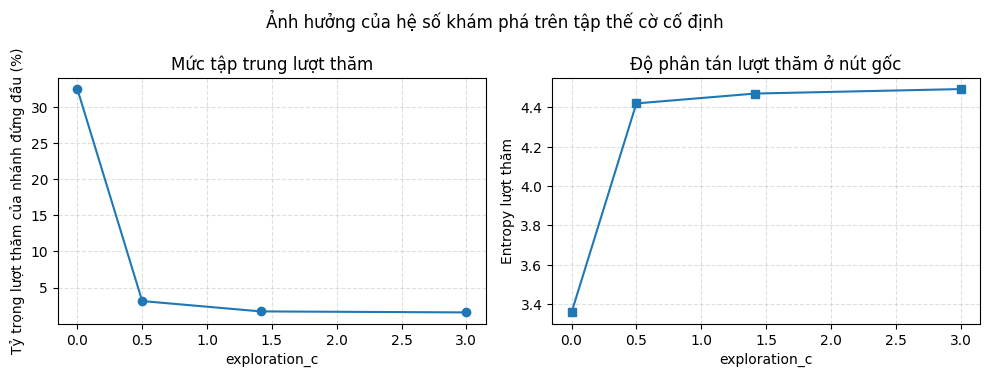

In [8]:
def summarize_root(agent: MCTSAgent, selected_action: int) -> dict:
    """Tính chỉ số từ get_root_stats(); xử lý an toàn khi last_root=None."""
    root_stats = agent.get_root_stats()
    total_visits = sum(item["visits"] for item in root_stats)
    if total_visits <= 0:
        return {
            "selected_action": int(selected_action),
            "root_children": len(root_stats),
            "top_action": None,
            "top_visit_share_pct": None,
            "visit_entropy": None,
        }

    probabilities = np.asarray(
        [item["visits"] / total_visits for item in root_stats], dtype=np.float64
    )
    entropy = -float(np.sum(probabilities * np.log(probabilities + 1e-12)))
    top_item = root_stats[0]
    return {
        "selected_action": int(selected_action),
        "root_children": len(root_stats),
        "top_action": int(top_item["action"]),
        "top_visit_share_pct": round(top_item["visits"] / total_visits * 100.0, 3),
        "visit_entropy": round(entropy, 4),
    }


c_sensitivity_rows = []
for c_value in EXPLORATION_VALUES:
    for position_index, position in enumerate(benchmark_positions):
        agent = MCTSAgent(
            num_rollouts=C_SENSITIVITY_ROLLOUTS,
            exploration_c=c_value,
            time_limit_sec=None,
            seed=BASE_SEED + position_index,
            name=f"MCTS_C{c_value}",
        )
        selected_action = agent.select_action(position.clone())
        root_summary = summarize_root(agent, selected_action)
        c_sensitivity_rows.append({
            "exploration_c": c_value,
            "position_id": position_index + 1,
            "num_rollouts_limit": C_SENSITIVITY_ROLLOUTS,
            "actual_rollouts": agent.last_search_count,
            "move_time_ms": round(agent.last_move_time_ms, 3),
            **root_summary,
        })

if c_sensitivity_rows:
    save_csv(TAB_DIR / "03_table_exploration_c_sensitivity.csv", c_sensitivity_rows)
    c_summary_rows = []
    for c_value in EXPLORATION_VALUES:
        selected = [row for row in c_sensitivity_rows if row["exploration_c"] == c_value]
        active_rollouts = [row["actual_rollouts"] for row in selected if row["actual_rollouts"] > 0]
        times = [row["move_time_ms"] for row in selected]
        visit_shares = [row["top_visit_share_pct"] for row in selected if row["top_visit_share_pct"] is not None]
        entropies = [row["visit_entropy"] for row in selected if row["visit_entropy"] is not None]
        c_summary_rows.append({
            "exploration_c": c_value,
            "positions": len(selected),
            "mean_move_time_ms": round(float(np.mean(times)), 3) if times else None,
            "mean_actual_rollouts_active": round(float(np.mean(active_rollouts)), 2) if active_rollouts else None,
            "mean_top_visit_share_pct": round(float(np.mean(visit_shares)), 2) if visit_shares else None,
            "mean_visit_entropy": round(float(np.mean(entropies)), 4) if entropies else None,
        })

    save_csv(TAB_DIR / "03_table_exploration_c_summary.csv", c_summary_rows)
    for row in c_summary_rows:
        print(row)

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].plot(
        [row["exploration_c"] for row in c_summary_rows],
        [row["mean_top_visit_share_pct"] if row["mean_top_visit_share_pct"] is not None else np.nan for row in c_summary_rows],
        marker="o",
    )
    axes[0].set_xlabel("exploration_c")
    axes[0].set_ylabel("Tỷ trọng lượt thăm của nhánh đứng đầu (%)")
    axes[0].set_title("Mức tập trung lượt thăm")
    axes[0].grid(True, linestyle="--", alpha=0.4)
    axes[1].plot(
        [row["exploration_c"] for row in c_summary_rows],
        [row["mean_visit_entropy"] if row["mean_visit_entropy"] is not None else np.nan for row in c_summary_rows],
        marker="s",
    )
    axes[1].set_xlabel("exploration_c")
    axes[1].set_ylabel("Entropy lượt thăm")
    axes[1].set_title("Độ phân tán lượt thăm ở nút gốc")
    axes[1].grid(True, linestyle="--", alpha=0.4)
    fig.suptitle("Ảnh hưởng của hệ số khám phá trên tập thế cờ cố định")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_fig_exploration_c_sensitivity.png", dpi=150)
    plt.show()
else:
    c_summary_rows = []
    print("Không có benchmark position để chạy Exploration Constant Sensitivity.")


## 5. So sánh các chế độ ngân sách tìm kiếm

`MCTSAgent` hỗ trợ ba kiểu dừng:

- **Fixed rollouts:** dừng khi đạt giới hạn số rollout.
- **Time budget:** dừng khi đạt `time_limit_sec`.
- **Combined:** dừng khi chạm một trong hai giới hạn.

Ba cấu hình chạy trên cùng các thế cờ cố định. Notebook ghi `last_search_count` và thời gian wall-clock cho mỗi quyết định. Các lượt có `last_search_count == 0` được đếm riêng vì có thể là forced move hoặc tactical shortcut, không phải một lần tìm kiếm cây.

Lưu ý: implementation kiểm tra đồng hồ sau mỗi rollout và bảo đảm ít nhất một rollout; vì vậy thời gian thực tế có thể vượt nhẹ `time_limit_sec`, nhất là khi một rollout đơn lẻ tốn nhiều thời gian.

{'budget_mode': 'fixed_rollouts', 'positions': 8, 'mean_rollouts_including_zero': 218.75, 'mean_rollouts_active_only': 250.0, 'shortcut_or_forced_count': 1, 'mean_move_time_ms': 597.483, 'p95_move_time_ms': 929.214}
{'budget_mode': 'time_budget', 'positions': 8, 'mean_rollouts_including_zero': 55.88, 'mean_rollouts_active_only': 63.86, 'shortcut_or_forced_count': 1, 'mean_move_time_ms': 132.163, 'p95_move_time_ms': 152.13}
{'budget_mode': 'combined', 'positions': 8, 'mean_rollouts_including_zero': 58.5, 'mean_rollouts_active_only': 66.86, 'shortcut_or_forced_count': 1, 'mean_move_time_ms': 132.096, 'p95_move_time_ms': 152.042}


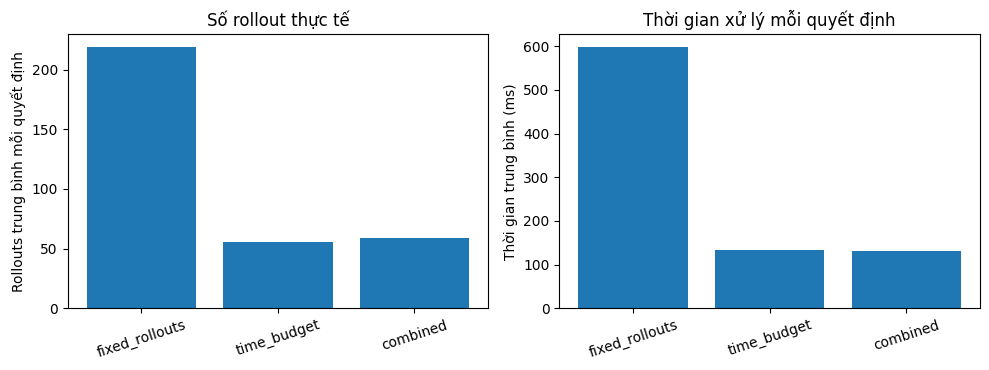

In [9]:
budget_configurations = [
    (
        "fixed_rollouts",
        {"num_rollouts": BUDGET_FIXED_ROLLOUTS, "time_limit_sec": None},
    ),
    (
        "time_budget",
        {"num_rollouts": None, "time_limit_sec": BUDGET_TIME_LIMIT_SEC},
    ),
    (
        "combined",
        {"num_rollouts": BUDGET_FIXED_ROLLOUTS, "time_limit_sec": BUDGET_TIME_LIMIT_SEC},
    ),
]

budget_detail_rows = []
for config_name, parameters in budget_configurations:
    for position_index, position in enumerate(benchmark_positions):
        agent = MCTSAgent(
            exploration_c=ROLLOUT_SENSITIVITY_C,
            seed=BASE_SEED + position_index,
            name=f"MCTS_{config_name}",
            **parameters,
        )
        start = time.perf_counter()
        selected_action = agent.select_action(position.clone())
        wall_time_ms = (time.perf_counter() - start) * 1000.0
        budget_detail_rows.append({
            "budget_mode": config_name,
            "position_id": position_index + 1,
            "selected_action": int(selected_action),
            "num_rollouts_limit": parameters["num_rollouts"],
            "time_limit_sec": parameters["time_limit_sec"],
            "actual_rollouts": agent.last_search_count,
            "is_shortcut_or_forced": agent.last_search_count == 0,
            "move_time_ms": round(wall_time_ms, 3),
        })

save_csv(TAB_DIR / "03_table_budget_modes_detail.csv", budget_detail_rows)
budget_summary_rows = []
for config_name, _ in budget_configurations:
    selected = [row for row in budget_detail_rows if row["budget_mode"] == config_name]
    active = [row["actual_rollouts"] for row in selected if row["actual_rollouts"] > 0]
    all_counts = [row["actual_rollouts"] for row in selected]
    times = [row["move_time_ms"] for row in selected]
    budget_summary_rows.append({
        "budget_mode": config_name,
        "positions": len(selected),
        "mean_rollouts_including_zero": round(float(np.mean(all_counts)), 2) if all_counts else None,
        "mean_rollouts_active_only": round(float(np.mean(active)), 2) if active else None,
        "shortcut_or_forced_count": sum(row["is_shortcut_or_forced"] for row in selected),
        "mean_move_time_ms": round(float(np.mean(times)), 3) if times else None,
        "p95_move_time_ms": round(float(np.percentile(times, 95)), 3) if times else None,
    })

save_csv(TAB_DIR / "03_table_budget_modes_summary.csv", budget_summary_rows)
for row in budget_summary_rows:
    print(row)

if budget_summary_rows:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    mode_labels = [row["budget_mode"] for row in budget_summary_rows]
    axes[0].bar(mode_labels, [row["mean_rollouts_including_zero"] or 0 for row in budget_summary_rows])
    axes[0].set_ylabel("Rollouts trung bình mỗi quyết định")
    axes[0].set_title("Số rollout thực tế")
    axes[0].tick_params(axis="x", rotation=18)
    axes[1].bar(mode_labels, [row["mean_move_time_ms"] or 0 for row in budget_summary_rows])
    axes[1].set_ylabel("Thời gian trung bình (ms)")
    axes[1].set_title("Thời gian xử lý mỗi quyết định")
    axes[1].tick_params(axis="x", rotation=18)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_fig_budget_modes.png", dpi=150)
    plt.show()


## 6. Đối kháng MCTSAgent và MinimaxAgent

Đây là thí nghiệm đối kháng chính của RQ2: **50 ván**, MCTS cầm X ở 25 ván và O ở 25 ván. Hai Agent phải thực sự áp dụng cùng ngân sách thời gian suy nghĩ cho mỗi nước; cấu hình trong notebook là `MINIMAX_TIME_BUDGET_SEC` giây/nước.

Trong ZIP được kiểm tra, `src/agents/minimax_agent.py` hiện chưa có lớp `MinimaxAgent`. Khi nhóm tích hợp, cần khai báo `MINIMAX_AGENT_FACTORY(time_limit_sec, seed)`. Factory phải trả về Agent có `select_action(env)` và thuộc tính `time_limit_sec` khớp ngân sách. **Chỉ có thuộc tính này chưa đủ:** cần đọc code `select_action()` để xác nhận Minimax thật sự kiểm tra deadline và dừng tìm kiếm theo thời gian, không chỉ giới hạn độ sâu.

Nếu chưa đáp ứng, notebook để `PENDING INTEGRATION / FAIR-BUDGET`, không dùng Minimax giả và không ghi kết quả so sánh công bằng.

In [10]:
minimax_summary = None
minimax_match_records = []

if MinimaxAgent is None or MINIMAX_AGENT_FACTORY is None:
    print(
        "PENDING INTEGRATION: MinimaxAgent/factory chưa sẵn sàng. "
        "Cần tích hợp class và xác nhận time budget trong select_action()."
    )
else:
    mcts_timed_agent = MCTSAgent(
        num_rollouts=None,
        time_limit_sec=MINIMAX_TIME_BUDGET_SEC,
        exploration_c=ROLLOUT_SENSITIVITY_C,
        seed=BASE_SEED,
        name="MCTS_TimeBudget",
    )
    minimax_agent = MINIMAX_AGENT_FACTORY(MINIMAX_TIME_BUDGET_SEC, BASE_SEED + 1)

    if not callable(getattr(minimax_agent, "select_action", None)):
        raise TypeError("MINIMAX_AGENT_FACTORY phải trả về Agent có select_action(env).")

    minimax_budget = getattr(minimax_agent, "time_limit_sec", None)
    budget_matches = (
        minimax_budget is not None
        and math.isclose(
            float(minimax_budget), MINIMAX_TIME_BUDGET_SEC,
            rel_tol=0.0, abs_tol=1e-9,
        )
    )

    if not budget_matches:
        print(
            "PENDING FAIR-BUDGET: thuộc tính time_limit_sec của Minimax không khớp "
            "ngân sách MCTS. Kiểm tra constructor/factory trước khi chạy."
        )
    else:
        print(
            "CẢNH BÁO: hãy xác nhận trong mã Minimax rằng select_action() "
            "thực sự kiểm tra deadline trước khi xem đây là so sánh công bằng."
        )
        minimax_summary, minimax_match_records = run_match_series(
            agent_a=mcts_timed_agent,
            agent_b=minimax_agent,
            num_games=MINIMAX_GAMES,
            series_name="MCTS_vs_Minimax_equal_time",
            base_seed=BASE_SEED + 5000,
        )
        save_csv(TAB_DIR / "03_table_mcts_vs_minimax.csv", [minimax_summary])
        save_jsonl(LOG_DIR / "03_logs_mcts_vs_minimax.jsonl", minimax_match_records)
        print(minimax_summary)


PENDING INTEGRATION: MinimaxAgent/factory chưa sẵn sàng. Cần tích hợp class và xác nhận time budget trong select_action().


## 7. Phân tích phân bố nước đi trên bàn cờ (Board Occupancy)

Phần này dùng biên bản của **một nhóm thí nghiệm duy nhất**:

1. Ưu tiên dữ liệu MCTS vs Minimax nếu 50 ván đã chạy.
2. Nếu Minimax chưa sẵn sàng, dùng riêng nhóm Rollouts Sensitivity có `N = OCCUPANCY_FALLBACK_ROLLOUT_BUDGET` (mặc định 600), không gộp bốn mức N vào cùng một heatmap.

Heatmap thể hiện số lần mỗi Agent chọn từng ô. Bảng vành đai dùng khoảng cách Chebyshev tới tâm `(5, 5)`. Đây là thống kê trên biên bản ván đã chạy, không phải vùng kiểm soát tuyệt đối của Agent.

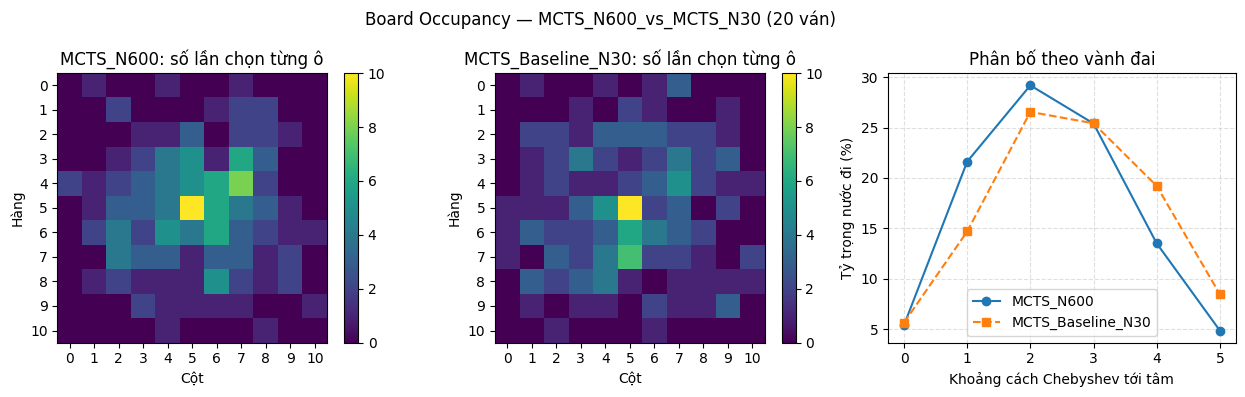

In [11]:
if minimax_match_records:
    occupancy_records = minimax_match_records
    occupancy_source_label = "MCTS vs Minimax"
elif rollout_match_records:
    fallback_series = f"MCTS_N{OCCUPANCY_FALLBACK_ROLLOUT_BUDGET}_vs_{rollout_opponent_tag}"
    occupancy_records = [
        record for record in rollout_match_records
        if record.get("series") == fallback_series
    ]
    occupancy_source_label = fallback_series
else:
    occupancy_records = []
    occupancy_source_label = None

if not occupancy_records:
    print(
        "PENDING DATA: chưa có nhóm ván phù hợp cho Board Occupancy. "
        "Chạy MCTS vs Minimax hoặc Rollouts Sensitivity với baseline đã chọn trước."
    )
else:
    first_record = occupancy_records[0]
    mcts_name = first_record["agent_a"]
    opponent_name = first_record["agent_b"]
    mcts_grid = np.zeros((11, 11), dtype=np.int32)
    opponent_grid = np.zeros((11, 11), dtype=np.int32)

    for record in occupancy_records:
        for move in record["moves"]:
            if move["agent"] == mcts_name:
                mcts_grid[move["row"], move["col"]] += 1
            elif move["agent"] == opponent_name:
                opponent_grid[move["row"], move["col"]] += 1

    occupancy_rows = []
    total_mcts_moves = int(mcts_grid.sum())
    total_opponent_moves = int(opponent_grid.sum())
    for ring in range(6):
        ring_mask = np.fromfunction(
            lambda r, c: np.maximum(np.abs(r - 5), np.abs(c - 5)) == ring,
            (11, 11), dtype=int,
        )
        mcts_count = int(mcts_grid[ring_mask].sum())
        opponent_count = int(opponent_grid[ring_mask].sum())
        occupancy_rows.append({
            "source": occupancy_source_label,
            "chebyshev_distance": ring,
            "cells_in_ring": int(ring_mask.sum()),
            "mcts_moves": mcts_count,
            "mcts_share_pct": round(mcts_count / total_mcts_moves * 100.0, 3) if total_mcts_moves else 0.0,
            "opponent_moves": opponent_count,
            "opponent_share_pct": round(opponent_count / total_opponent_moves * 100.0, 3) if total_opponent_moves else 0.0,
        })

    save_csv(TAB_DIR / "03_table_board_occupancy.csv", occupancy_rows)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    image_a = axes[0].imshow(mcts_grid)
    axes[0].set_title(f"{mcts_name}: số lần chọn từng ô")
    axes[0].set_xlabel("Cột")
    axes[0].set_ylabel("Hàng")
    axes[0].set_xticks(range(11))
    axes[0].set_yticks(range(11))
    fig.colorbar(image_a, ax=axes[0], fraction=0.046)

    image_b = axes[1].imshow(opponent_grid)
    axes[1].set_title(f"{opponent_name}: số lần chọn từng ô")
    axes[1].set_xlabel("Cột")
    axes[1].set_ylabel("Hàng")
    axes[1].set_xticks(range(11))
    axes[1].set_yticks(range(11))
    fig.colorbar(image_b, ax=axes[1], fraction=0.046)

    rings = [row["chebyshev_distance"] for row in occupancy_rows]
    axes[2].plot(rings, [row["mcts_share_pct"] for row in occupancy_rows], "o-", label=mcts_name)
    axes[2].plot(rings, [row["opponent_share_pct"] for row in occupancy_rows], "s--", label=opponent_name)
    axes[2].set_xlabel("Khoảng cách Chebyshev tới tâm")
    axes[2].set_ylabel("Tỷ trọng nước đi (%)")
    axes[2].set_title("Phân bố theo vành đai")
    axes[2].set_xticks(range(6))
    axes[2].grid(True, linestyle="--", alpha=0.4)
    axes[2].legend()

    fig.suptitle(f"Board Occupancy — {occupancy_source_label} ({len(occupancy_records)} ván)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_fig_board_occupancy.png", dpi=150)
    plt.show()


## 8. Explainability qua `get_root_stats()`

`get_root_stats()` trả về thống kê các nhánh con tại nút gốc, gồm `action`, `visits`, `wins` và `value`. Phần này dùng một thế cờ trung cuộc cố định để quan sát cách MCTS phân bổ lượt thăm.

`value` là giá trị tích lũy theo góc nhìn người vừa thực hiện nước đi tạo ra nhánh; do đó có thể âm hoặc dương. Nếu MCTS chọn forced move hoặc tactical shortcut, `last_root` có thể là `None` và danh sách thống kê sẽ rỗng. Notebook kiểm tra điều kiện này trước khi vẽ.

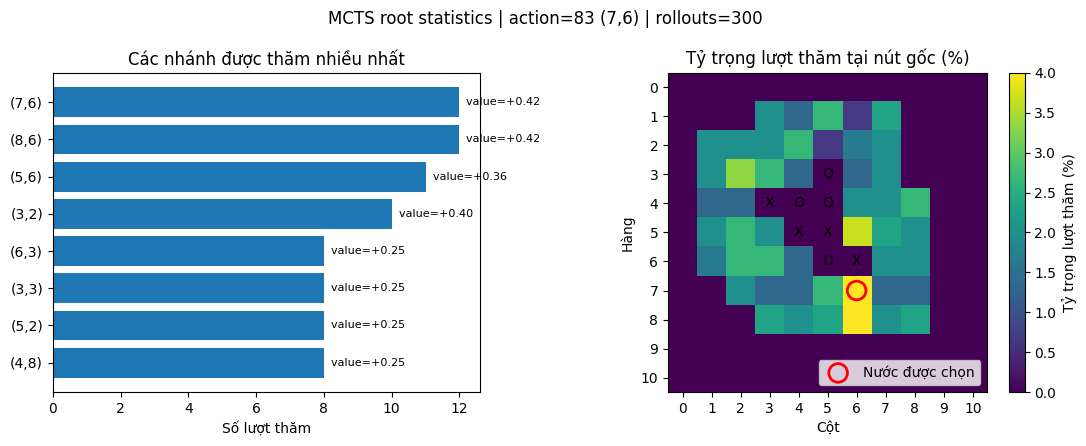

In [12]:
explain_env = build_position([60, 49, 59, 48, 72, 71, 47, 38])
explain_agent = MCTSAgent(
    num_rollouts=EXPLAINABILITY_ROLLOUTS,
    exploration_c=EXPLAINABILITY_C,
    time_limit_sec=None,
    seed=BASE_SEED,
    name="MCTS_Explainability",
)
explain_action = explain_agent.select_action(explain_env)
explain_stats = explain_agent.get_root_stats()

total_root_visits = sum(row["visits"] for row in explain_stats)
if not explain_stats or total_root_visits <= 0:
    print(
        "Không có root statistics hợp lệ ở thế cờ này "
        "(last_root có thể là None do forced move/tactical shortcut)."
    )
else:
    save_csv(TAB_DIR / "03_table_mcts_root_stats.csv", explain_stats)
    visit_map = np.zeros((11, 11), dtype=np.float64)
    for row in explain_stats:
        r, c = divmod(row["action"], 11)
        visit_map[r, c] = row["visits"] / total_root_visits * 100.0

    top_rows = explain_stats[:8]
    labels = [f"({row['action'] // 11},{row['action'] % 11})" for row in top_rows]
    visits = [row["visits"] for row in top_rows]
    values = [row["value"] for row in top_rows]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    bars = axes[0].barh(labels, visits)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Số lượt thăm")
    axes[0].set_title("Các nhánh được thăm nhiều nhất")
    for bar, value in zip(bars, values):
        axes[0].text(
            bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  value={value:+.2f}", va="center", fontsize=8,
        )

    image = axes[1].imshow(visit_map, vmin=0)
    axes[1].set_xticks(range(11))
    axes[1].set_yticks(range(11))
    axes[1].set_xlabel("Cột")
    axes[1].set_ylabel("Hàng")
    axes[1].set_title("Tỷ trọng lượt thăm tại nút gốc (%)")
    for r in range(11):
        for c in range(11):
            if explain_env.board[r, c] == 1:
                axes[1].text(c, r, "X", ha="center", va="center")
            elif explain_env.board[r, c] == -1:
                axes[1].text(c, r, "O", ha="center", va="center")
            elif visit_map[r, c] >= 5:
                axes[1].text(c, r, f"{visit_map[r, c]:.0f}", ha="center", va="center", fontsize=8)

    selected_row, selected_col = divmod(int(explain_action), 11)
    axes[1].scatter(
        selected_col, selected_row, s=180,
        facecolors="none", edgecolors="red", linewidths=2,
        label="Nước được chọn",
    )
    axes[1].legend(loc="lower right")
    fig.colorbar(image, ax=axes[1], fraction=0.046, label="Tỷ trọng lượt thăm (%)")
    fig.suptitle(
        f"MCTS root statistics | action={explain_action} "
        f"({selected_row},{selected_col}) | rollouts={explain_agent.last_search_count}"
    )
    plt.tight_layout()
    plt.savefig(FIG_DIR / "03_fig_mcts_explainability.png", dpi=150)
    plt.show()


## 9. Tổng hợp và hướng dẫn diễn giải

- Chỉ kết luận về ảnh hưởng của `num_rollouts` sau khi Rollouts Sensitivity đã chạy với `RuleBasedAgent` thật.
- Phân biệt **Win Rate** và **Score Rate**; Score Rate có tính kết quả hòa.
- Với 20 ván/cấu hình, khoảng tin cậy có thể còn rộng; không diễn giải chênh lệch nhỏ như bằng chứng chắc chắn cấu hình này mạnh hơn cấu hình khác.
- Chỉ kết luận MCTS vs Minimax công bằng khi Minimax thực sự áp dụng cùng time budget trong `select_action()`.
- Exploration Constant và Budget Comparison đo hành vi tìm kiếm/chi phí trên tập thế cờ, không phải tỷ lệ thắng thi đấu.
- Board Occupancy lấy dữ liệu từ đúng một nhóm ván và phải ghi rõ nguồn dữ liệu trong báo cáo.

Các kết quả đang `PENDING` không được đưa vào bảng kết luận như số liệu thực nghiệm.

In [13]:
print("=== KIỂM TRA CHIẾN THUẬT ===")
passed_count = sum(bool(row["condition_met"]) for row in tactical_rows)
print(f"Điều kiện kiểm tra đạt: {passed_count}/{len(tactical_rows)}")

print("\n=== TRẠNG THÁI THÍ NGHIỆM ===")
print(
    f"Rollouts Sensitivity vs {rollout_opponent_tag if 'rollout_opponent_tag' in globals() else ROLLOUT_BASELINE_MODE}",
    "COMPLETED" if rollout_sensitivity_rows else "PENDING INTEGRATION",
)
print(
    "Exploration Constant:",
    "COMPLETED" if c_sensitivity_rows else "NO DATA",
)
print(
    "Budget Comparison:",
    "COMPLETED" if budget_detail_rows else "NO DATA",
)
print(
    "MCTS vs MinimaxAgent:",
    "COMPLETED" if minimax_summary is not None else "PENDING INTEGRATION / FAIR-BUDGET",
)
print(
    "Board Occupancy:",
    "COMPLETED" if occupancy_records else "PENDING DATA",
)

if rollout_sensitivity_rows:
    print("\n=== ROLLOUTS SENSITIVITY — SỐ LIỆU ĐÃ ĐO ===")
    for row in rollout_sensitivity_rows:
        print(
            f"N={row['num_rollouts']}: Win Rate={row['win_rate_pct']}%, "
            f"Score Rate={row['score_rate_pct']}%, "
            f"Mean Time={row['mean_move_time_ms']} ms, "
            f"W/D/L={row['wins']}/{row['draws']}/{row['losses']}"
        )
    best_observed = max(rollout_sensitivity_rows, key=lambda row: row["win_rate_pct"])
    print(
        "Highest observed Win Rate in this sample:",
        f"N={best_observed['num_rollouts']} ({best_observed['win_rate_pct']}%)"
    )
    print("Lưu ý: đây là mô tả mẫu đã chạy, không tự khẳng định ưu thế thống kê.")

if minimax_summary is not None:
    print("\n=== MCTS VS MINIMAX ===")
    print(minimax_summary)

print("\n=== FILE CSV ĐÃ TẠO ===")
for path in sorted(TAB_DIR.glob("03_*.csv")):
    print("-", path.name)

print("\n=== HÌNH ĐÃ TẠO ===")
for path in sorted(FIG_DIR.glob("03_*.png")):
    print("-", path.name)

print("\n=== LOG JSONL ĐÃ TẠO ===")
for path in sorted(LOG_DIR.glob("03_*.jsonl")):
    print("-", path.name)


=== KIỂM TRA CHIẾN THUẬT ===
Điều kiện kiểm tra đạt: 4/4

=== TRẠNG THÁI THÍ NGHIỆM ===
Rollouts Sensitivity vs MCTS_N30 COMPLETED
Exploration Constant: COMPLETED
Budget Comparison: COMPLETED
MCTS vs MinimaxAgent: PENDING INTEGRATION / FAIR-BUDGET
Board Occupancy: COMPLETED

=== ROLLOUTS SENSITIVITY — SỐ LIỆU ĐÃ ĐO ===
N=50: Win Rate=50.0%, Score Rate=50.0%, Mean Time=119.38 ms, W/D/L=10/0/10
N=150: Win Rate=75.0%, Score Rate=75.0%, Mean Time=318.305 ms, W/D/L=15/0/5
N=300: Win Rate=90.0%, Score Rate=90.0%, Mean Time=634.144 ms, W/D/L=18/0/2
N=600: Win Rate=90.0%, Score Rate=90.0%, Mean Time=1142.8 ms, W/D/L=18/0/2
Highest observed Win Rate in this sample: N=300 (90.0%)
Lưu ý: đây là mô tả mẫu đã chạy, không tự khẳng định ưu thế thống kê.

=== FILE CSV ĐÃ TẠO ===
- 03_table_board_occupancy.csv
- 03_table_budget_modes_detail.csv
- 03_table_budget_modes_summary.csv
- 03_table_exploration_c_sensitivity.csv
- 03_table_exploration_c_summary.csv
- 03_table_mcts_root_stats.csv
- 03_table_mcts